# ARTI 502 | Topic 6: Hate Speech Detection with LSTM and BERT
**Kaggle Notebooks edition** | Person 1: LSTM | Person 2: BERT

**Task:** Classify English tweets as **hate (1)** versus **non-hate (0)** with TweetEval's `hate` subset. This is **hate-speech detection**, not comprehensive toxicity classification.

**Included:** exploratory dataset analysis, leakage diagnostics, reproducible preprocessing, training-only chi-squared lexical feature ranking and ablations, LSTM hyperparameter experiments, BERT fine-tuning and hyperparameter experiments, validation-based model selection, held-out test evaluation, curves, confusion matrices, an inference demo, and report-ready files.

### Kaggle setup (read first)
1. Open **Settings → Accelerator → GPU T4 x2**. One of the T4 cards is enough; the code will use one GPU automatically. The second GPU is not automatically used.
2. Turn **Internet ON** in notebook settings to download the TweetEval dataset and pretrained `bert-base-uncased` model. If the option is unavailable, verify your account or use Kaggle input attachments with an offline-compatible notebook.
3. Run cells **in order**, rather than using **Run All** the first time. Make sure the package check, GPU check, and dataset download succeed before any training.
4. All created files are written under **`/kaggle/working/ARTI502_Topic6_Outputs/`**. Use **Save Version** to preserve notebook outputs and artifacts; download your ZIP from the **Output** panel before ending the session. Files in the temporary working directory do not persist unless saved/exported.
5. If you encounter a dependency installation error, stop and share the traceback. Do not blindly upgrade the entire Kaggle environment.

**Research integrity:** No results are fabricated. The notebook must complete actual training to produce report metrics and figures. Select models on **training + validation** only and evaluate the selected models on the **held-out test** once.

**Dataset:** [TweetEval dataset card](https://huggingface.co/datasets/cardiffnlp/tweet_eval). Reference: Barbieri et al. (2020), *TweetEval: Unified Benchmark and Comparative Evaluation for Tweet Classification* ([paper](https://aclanthology.org/2020.findings-emnlp.148/)).

**Team workflow:** Kaggle notebook collaboration shares code, not live Python variables or GPU runtime. The complete notebook should ultimately be run in one session, or checkpoint files and model metadata must be transferred explicitly. The training sections may consume a meaningful amount of GPU quota.

## 0. Kaggle dependencies and environment

**This replaces the Colab-specific `pip install -U` cell.** Kaggle already has most scientific packages installed; this setup checks what's present and installs only missing/incompatible packages to avoid unnecessarily upgrading `pandas`, `matplotlib`, and unrelated preinstalled packages. If any packages are installed or changed, restart the session **once** and continue with the import cell below. Re-running this cell after restart should report that the packages are already available.

In [ ]:
# Kaggle-friendly dependency check: avoid upgrading the entire preinstalled environment.
import importlib.metadata as metadata
import subprocess
import sys
from packaging.specifiers import SpecifierSet

# distribution_name, supported version range (conservative: tested API expects Transformers 4.x)
REQUIRED = {
    'datasets': '>=3.0,<5',
    'transformers': '>=4.45,<5',
    'torch': '>=2.0',
    'scikit-learn': '>=1.3',
    'pandas': '>=2.0',
    'matplotlib': '>=3.7',
    'tqdm': '>=4.66',
    'safetensors': '>=0.4',
}
missing = []
for package, requirement in REQUIRED.items():
    try:
        version = metadata.version(package)
        compatible = version in SpecifierSet(requirement)
        print(f'{package}: {version}' + ('' if compatible else ' (needs compatible version)'))
        if not compatible:
            missing.append(f'{package}{requirement}')
    except metadata.PackageNotFoundError:
        print(f'{package}: not installed')
        missing.append(f'{package}{requirement}')

if missing:
    print('Installing only:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    print('IMPORTANT: Restart Kaggle session once, then resume from the next cell.')
else:
    print('Core packages available. No pip changes needed.')

datasets: 4.8.5
transformers: 5.20.2 (needs compatible version)
torch: 2.11.0+cu130
scikit-learn: 1.6.1
pandas: 2.3.3
matplotlib: 3.10.0
tqdm: 4.67.3
safetensors: 0.8.0
Installing only: ['transformers>=4.45,<5']


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


IMPORTANT: Restart Kaggle session once, then resume from the next cell.


In [ ]:
import os
import re
import gc
import json
import math
import time
import random
import shutil
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, confusion_matrix,
    classification_report, roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: BERT fine-tuning on CPU will be considerably more demanding.")

IS_KAGGLE = Path('/kaggle/working').exists()
if not IS_KAGGLE:
    print('WARNING: Kaggle working directory not detected; running in fallback mode.')
OUTPUT_DIR = (Path('/kaggle/working') if IS_KAGGLE else Path.cwd()) / 'ARTI502_Topic6_Outputs'
FIG_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR = OUTPUT_DIR / 'tables'
MODEL_DIR = OUTPUT_DIR / 'models'
for folder in (FIG_DIR, TABLE_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Full dataset by default. Change to e.g. 1500/300/300 only for a quick code smoke test.
TRAIN_LIMIT = None
VAL_LIMIT = None
TEST_LIMIT = None

# Turn OFF optional ablations to reduce compute, but keep ON for the fuller report experiment.
RUN_LSTM_FEATURE_EXPERIMENTS = True
RUN_BERT_FEATURE_EXPERIMENTS = True

print('Output folder:', OUTPUT_DIR)
print('Kaggle environment:', IS_KAGGLE)
print('CUDA device count:', torch.cuda.device_count())
if device.type != 'cuda':
    print('WARNING: GPU not connected. Stop before training BERT and enable Accelerator: GPU T4 x2.')
print('Reminder: enable Kaggle Internet so the dataset and pretrained BERT can be downloaded.')

Torch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4
Output folder: /kaggle/working/ARTI502_Topic6_Outputs
Kaggle environment: True
CUDA device count: 2
Reminder: enable Kaggle Internet so the dataset and pretrained BERT can be downloaded.


## 1. Dataset loading and audit | Shared / Person 1
**Expected full-dataset splits:** 9,000 train, 1,000 validation, 2,970 test for TweetEval's `hate` configuration. **Labels:** 0 = non-hate; 1 = hate. Do **not** randomly re-split or fit word selection on test data.

In [ ]:
raw = load_dataset('cardiffnlp/tweet_eval', 'hate')

def to_frame(split_name, limit=None):
    frame = raw[split_name].to_pandas()[['text', 'label']].copy()
    if limit is not None:
        frame = frame.sample(n=min(limit, len(frame)), random_state=SEED).sort_index().reset_index(drop=True)
    return frame

train_df = to_frame('train', TRAIN_LIMIT)
val_df   = to_frame('validation', VAL_LIMIT)
test_df  = to_frame('test', TEST_LIMIT)
LABEL_NAMES = ['Non-hate', 'Hate']
assert set(train_df.label.unique()).issubset({0, 1})

split_table = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Examples': [len(train_df), len(val_df), len(test_df)],
    'Non-hate': [(df.label == 0).sum() for df in [train_df,val_df]] + [np.nan],
    'Hate': [(df.label == 1).sum() for df in [train_df,val_df]] + [np.nan],
})
split_table.to_csv(TABLE_DIR / 'dataset_splits.csv', index=False)
display(split_table)
print('Dataset columns:', list(train_df.columns))

README.md: 0.00B [00:00, ?B/s]

hate/train-00000-of-00001.parquet:   0%|          | 0.00/816k [00:00<?, ?B/s]

hate/test-00000-of-00001.parquet:   0%|          | 0.00/278k [00:00<?, ?B/s]

hate/validation-00000-of-00001.parquet:   0%|          | 0.00/103k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2970 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

,Split,Examples,Non-hate,Hate
0,Train,9000,5217.0,3783.0
1,Validation,1000,573.0,427.0
2,Test,2970,NaN,NaN


Dataset columns: ['text', 'label']


In [ ]:
print(test_df["label"].value_counts(dropna=False))
print(test_df["label"].unique())

label
0    1718
1    1252
Name: count, dtype: int64
[0 1]


In [ ]:
# Diagnostics ONLY. Keep the benchmark's fixed splits; do not delete rows silently.
for name, frame in [('train', train_df), ('validation', val_df)]:
    print(f'{name}: missing text={frame.text.isna().sum()}, duplicate text={frame.text.duplicated().sum()}, '          f'conflicting labels={frame.groupby("text").label.nunique().gt(1).sum()}')

for (a_name, a), (b_name, b) in [
    (('train',train_df),('validation',val_df)),
    (('train',train_df),('test',test_df)),
    (('validation',val_df),('test',test_df))
]:
    overlapping = len(set(a.text) & set(b.text))
    print(f'Exact text overlap {a_name}/{b_name}: {overlapping}')

# Test texts are checked for exact cross-split overlap but test LABELS remain sealed.
# NEVER use the test labels or their distribution to select hyperparameters/features/thresholds.

train: missing text=0, duplicate text=13, conflicting labels=1
validation: missing text=0, duplicate text=0, conflicting labels=0
Exact text overlap train/validation: 3
Exact text overlap train/test: 232
Exact text overlap validation/test: 0


### 1.1 Minimal and consistent preprocessing
URLs and user mentions are standardized; casing is lowercased. We retain punctuation and avoid removing stop words, since negation, context and offensive expressions matter. **Feature selection** experiments below intentionally remove some lexical tokens only for controlled ablation.

In [ ]:
URL_RE = re.compile(r'https?://\S+|www\.\S+', flags=re.IGNORECASE)
USER_RE = re.compile(r'@\w+', flags=re.UNICODE)
SPACE_RE = re.compile(r'\s+')
WORD_PUNCT_RE = re.compile(r'\b\w+\b|[^\w\s]', flags=re.UNICODE)

def clean_text(text):
    text = str(text).lower()
    text = URL_RE.sub(' url ', text)
    text = USER_RE.sub(' user ', text)
    return SPACE_RE.sub(' ', text).strip()

for frame in (train_df, val_df, test_df):
    frame['clean_text'] = frame['text'].map(clean_text)
    frame['char_length'] = frame['clean_text'].str.len()
    frame['word_length'] = frame['clean_text'].str.split().str.len()

# Only observational statistics; no model fitting on validation/test texts.
stat_rows = []
for name, frame in [('Train',train_df), ('Validation',val_df), ('Test',test_df)]:
    for field in ['char_length', 'word_length']:
        s = frame[field]
        stat_rows.append({
            'Split': name, 'Attribute': field, 'Mean': s.mean(),
            'Median': s.median(), 'Std': s.std(), 'Min': s.min(), 'Max': s.max()
        })
stats_df = pd.DataFrame(stat_rows).round(2)
stats_df.to_csv(TABLE_DIR / 'dataset_text_statistics.csv', index=False)
display(stats_df)

,Split,Attribute,Mean,Median,Std,Min,Max
0,Train,char_length,121.61,109.0,66.55,0,303
1,Train,word_length,20.86,19.0,10.89,0,63
2,Validation,char_length,140.04,123.0,73.11,0,487
3,Validation,word_length,24.18,22.0,13.05,0,93
4,Test,char_length,130.17,115.0,71.70,14,463
5,Test,word_length,21.45,20.0,10.57,1,90


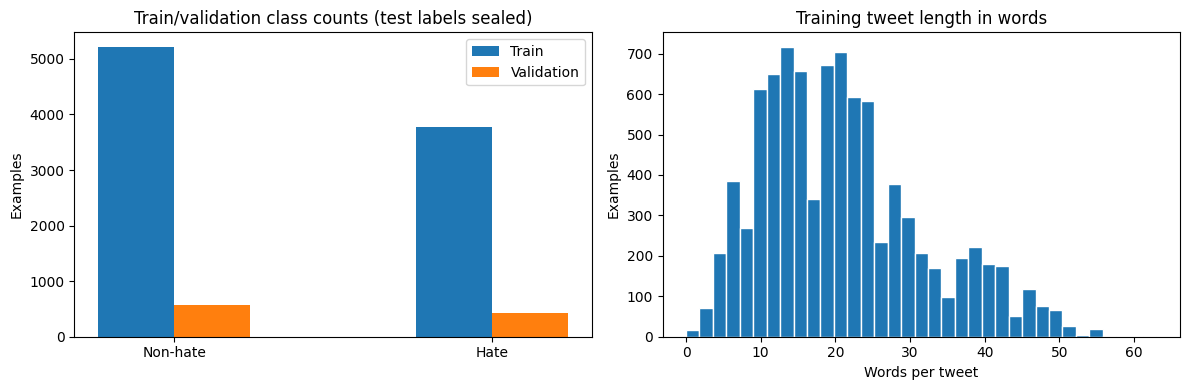

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for frame, name in [(train_df,'Train'), (val_df,'Validation')]:
    axes[0].bar(np.arange(2) + {'Train':-0.12,'Validation':0.12}[name],
                [sum(frame.label == 0), sum(frame.label == 1)],
                width=0.24, label=name)
axes[0].set_xticks([0,1], LABEL_NAMES)
axes[0].set_title('Train/validation class counts (test labels sealed)')
axes[0].set_ylabel('Examples')
axes[0].legend()
axes[1].hist(train_df.word_length, bins=35, edgecolor='white')
axes[1].set_title('Training tweet length in words')
axes[1].set_xlabel('Words per tweet')
axes[1].set_ylabel('Examples')
plt.tight_layout()
plt.savefig(FIG_DIR / '01_dataset_overview.png', dpi=170, bbox_inches='tight')
plt.show()

## 2. Train-only word-feature ranking | Shared for Section 6.1
The report template asks for feature-selection experiments. For text, raw columns do not exist like tabular data. We therefore rank **training-set unigram lexical features** using chi-squared association with the class label, retain the top half / quarter of candidate words, and compare against full text.

**Methodological caveat:** This is a *filter-based lexical feature selection/ablation*, **not** model-based recursive feature elimination (RFE). The exact RFE algorithm described in the general-purpose template is not computationally practical to apply directly to BERT token embeddings. Discuss this adaptation clearly in the report. Removed words can impair contextual BERT, so full text may perform best; report the result whichever direction it goes.

In [ ]:
vectorizer = CountVectorizer(
    binary=True, lowercase=False, token_pattern=r'(?u)\b\w+\b',
    min_df=2, max_features=12000
)
X_terms = vectorizer.fit_transform(train_df.clean_text)
y_terms = train_df.label.to_numpy(dtype=int)
term_scores, term_pvalues = chi2(X_terms, y_terms)
term_scores = np.nan_to_num(term_scores, nan=0.0, posinf=0.0)
term_names = vectorizer.get_feature_names_out()
rank_indices = np.argsort(-term_scores, kind='stable')
ranked_words = term_names[rank_indices]

feature_ranking = pd.DataFrame({
    'Term': ranked_words, 'Chi2': term_scores[rank_indices],
    'p_value': term_pvalues[rank_indices]
})
feature_ranking.to_csv(TABLE_DIR / 'train_only_word_feature_ranking.csv', index=False)
print('Candidate lexical features:', len(ranked_words))
display(feature_ranking.head(15))

N_FEATURES = len(ranked_words)
selected_word_sets = {
    'full': None,
    'top_half': set(ranked_words[:max(1, N_FEATURES//2)]),
    'top_quarter': set(ranked_words[:max(1, N_FEATURES//4)]),
}

def filter_selected_words(text, selected_words):
    if selected_words is None:
        return text
    tokens = WORD_PUNCT_RE.findall(text)
    # Preserve punctuation/emoji; remove unselected lexical tokens.
    kept = [tok for tok in tokens if (not tok.isalnum()) or (tok in selected_words)]
    return ' '.join(kept) if kept else 'empty'

def texts_for_variant(frame, variant):
    selection = selected_word_sets[variant]
    if selection is None:
        return frame.clean_text.tolist()
    return [filter_selected_words(t, selection) for t in frame.clean_text.tolist()]

feature_sizes = pd.DataFrame([
    {'Variant': name, 'Selected_training_unigrams': N_FEATURES if s is None else len(s)}
    for name,s in selected_word_sets.items()
])
feature_sizes.to_csv(TABLE_DIR / 'feature_subset_sizes.csv', index=False)
display(feature_sizes)
# Save vocabulary subsets so exported checkpoints can be used after restarting the runtime.
with open(MODEL_DIR / 'selected_lexical_features.json', 'w', encoding='utf-8') as f:
    json.dump({k: (None if v is None else sorted(v)) for k,v in selected_word_sets.items()}, f)


Candidate lexical features: 7565


,Term,Chi2,p_value
0,bitch,543.313391,3.586041e-120
1,buildthatwall,457.849326,1.412269e-101
2,immigrant,284.121770,9.493228e-64
3,maga,226.816652,2.948481e-51
4,buildthewall,225.956471,4.541530e-51
5,nodaca,177.899286,1.393497e-40
6,illegal,171.875096,2.881640e-39
7,womensuck,151.126266,9.835371e-35
8,illegals,136.801478,1.332639e-31
9,hoe,133.452863,7.197136e-31


,Variant,Selected_training_unigrams
0,full,7565
1,top_half,3782
2,top_quarter,1891


## 3. Common scoring and plotting utilities
**Primary validation metric:** F1 for `Hate` (positive class = 1). Also report accuracy, macro F1, precision, recall, ROC-AUC, and average precision because class imbalance can distort accuracy. We use a fixed probability threshold of **0.50**; it is not tuned on test data.

In [ ]:
def compute_metrics(y_true, hate_probs, threshold=0.5):
    y_true = np.asarray(y_true, dtype=int)
    hate_probs = np.asarray(hate_probs, dtype=float)
    y_pred = (hate_probs >= threshold).astype(int)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[1], average='binary', zero_division=0
    )
    macro = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)[2]
    out = {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_hate': float(precision), 'recall_hate': float(recall),
        'f1_hate': float(f1), 'f1_macro': float(macro),
        'roc_auc': float(roc_auc_score(y_true, hate_probs)) if len(np.unique(y_true)) > 1 else np.nan,
        'average_precision': float(average_precision_score(y_true, hate_probs)) if len(np.unique(y_true)) > 1 else np.nan,
    }
    return out

def show_history(history, prefix):
    hist = pd.DataFrame(history)
    hist.to_csv(TABLE_DIR / f'{prefix}_training_history.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(10,3.5))
    axes[0].plot(hist.epoch, hist.train_loss, marker='o')
    axes[0].set(title='Training loss', xlabel='Epoch', ylabel='Loss')
    axes[1].plot(hist.epoch, hist.val_f1_hate, marker='o', label='Hate F1')
    axes[1].plot(hist.epoch, hist.val_f1_macro, marker='s', label='Macro F1')
    axes[1].set(title='Validation performance', xlabel='Epoch', ylabel='F1')
    axes[1].legend()
    plt.suptitle(prefix.replace('_',' '))
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{prefix}_curves.png', dpi=170, bbox_inches='tight')
    plt.show()

def draw_final_plots(y_true, probabilities, model_name):
    preds = (np.asarray(probabilities) >= 0.5).astype(int)
    cm = confusion_matrix(y_true, preds, labels=[0,1])
    fig, axes = plt.subplots(1, 3, figsize=(16,4.2))
    im = axes[0].imshow(cm, cmap='Blues')
    axes[0].set_xticks([0,1], LABEL_NAMES)
    axes[0].set_yticks([0,1], LABEL_NAMES)
    axes[0].set(xlabel='Predicted', ylabel='True', title='Confusion matrix')
    for i in range(2):
        for j in range(2):
            axes[0].text(j, i, str(cm[i,j]), ha='center', va='center',
                         color='white' if cm[i,j] > cm.max()/2 else 'black')
    fig.colorbar(im, ax=axes[0], fraction=0.046)
    if len(np.unique(y_true)) > 1:
        fpr, tpr, _ = roc_curve(y_true, probabilities)
        prec, recall, _ = precision_recall_curve(y_true, probabilities)
        axes[1].plot(fpr, tpr)
        axes[1].plot([0,1],[0,1], linestyle='--', color='gray')
        axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve')
        axes[2].plot(recall,prec)
        axes[2].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curve')
    plt.suptitle(f'{model_name} | Held-out test set')
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'final_{model_name.lower()}_test_plots.png', dpi=170, bbox_inches='tight')
    plt.show()
    print(classification_report(y_true, preds, labels=[0,1], target_names=LABEL_NAMES, zero_division=0))

# Class weights calculated solely from training labels. Apply to BOTH methods for consistency.
class_counts = np.bincount(train_df.label.to_numpy(dtype=int), minlength=2)
class_weights = torch.tensor(len(train_df)/(2 * np.maximum(class_counts, 1)), dtype=torch.float)
print('Train-only class counts:', class_counts, '| CE weights:', class_weights.tolist())

Train-only class counts: [5217 3783] | CE weights: [0.8625646829605103, 1.1895321607589722]


# PERSON 1 | LSTM model (Sections 4–6)
Person 1 should complete and inspect this section first. A BiLSTM is a valid LSTM-based classifier (recurrent neural network); it uses trainable word embeddings and concatenated forward/backward hidden states.

## 4. LSTM vocabulary and PyTorch DataLoaders
Vocabulary is created **only from training text**. Validation and test words that are unseen map to `<UNK>`. We retain a constant vocabulary across feature-selection experiments to isolate the effect of removing lexical words.

In [ ]:
PAD_ID, UNK_ID = 0, 1
VOCAB_LIMIT = 15000
LSTM_MAX_LEN = 80
LSTM_BATCH_SIZE = 64

def lstm_tokens(text):
    return WORD_PUNCT_RE.findall(text)

word_counter = Counter(tok for t in train_df.clean_text for tok in lstm_tokens(t))
vocab_items = sorted(word_counter.items(), key=lambda p: (-p[1],p[0]))[:VOCAB_LIMIT-2]
stoi = {'<PAD>': PAD_ID, '<UNK>': UNK_ID}
stoi.update({tok:i+2 for i,(tok,_) in enumerate(vocab_items)})
itos = {i:s for s,i in stoi.items()}
print('Vocabulary size:', len(stoi))

def encode_lstm(text, max_len=LSTM_MAX_LEN):
    ids = [stoi.get(token, UNK_ID) for token in lstm_tokens(text)[:max_len]]
    if not ids:
        ids = [UNK_ID]
    length = len(ids)
    ids += [PAD_ID] * (max_len-length)
    return ids, length

class TextLSTMDataset(Dataset):
    def __init__(self, texts, labels, max_len=LSTM_MAX_LEN):
        encoded = [encode_lstm(t, max_len) for t in texts]
        self.input_ids = torch.tensor([e[0] for e in encoded], dtype=torch.long)
        self.lengths = torch.tensor([e[1] for e in encoded], dtype=torch.long)
        self.labels = torch.tensor(np.asarray(labels, dtype=int), dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.lengths[idx], self.labels[idx]

def lstm_loaders(variant, batch_size=LSTM_BATCH_SIZE):
    tr = TextLSTMDataset(texts_for_variant(train_df, variant), train_df.label.to_numpy())
    va = TextLSTMDataset(texts_for_variant(val_df, variant), val_df.label.to_numpy())
    return (
        DataLoader(tr, batch_size=batch_size, shuffle=True),
        DataLoader(va, batch_size=batch_size, shuffle=False)
    )

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=1,
                            batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim*2, 2)

    def forward(self, ids, lengths):
        emb = self.dropout(self.embedding(ids))
        packed = nn.utils.rnn.pack_padded_sequence(
            emb, lengths.detach().cpu().clamp(min=1), batch_first=True, enforce_sorted=False
        )
        _, (hidden, _) = self.lstm(packed)
        last_hidden = torch.cat((hidden[-2],hidden[-1]), dim=1)
        return self.classifier(self.dropout(last_hidden))

Vocabulary size: 15000


## 5. LSTM training functions and hyperparameter search
Each trial starts from a fresh randomly initialized model and selects the best epoch by **validation Hate F1**. Only improved validation checkpoints are retained.

lstm_h96_lr1e3 epoch 1:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h96_lr1e3 | epoch 1 | loss=0.6309 | val Hate F1=0.6395


lstm_h96_lr1e3 epoch 2:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h96_lr1e3 | epoch 2 | loss=0.5298 | val Hate F1=0.6736


lstm_h96_lr1e3 epoch 3:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h96_lr1e3 | epoch 3 | loss=0.4611 | val Hate F1=0.6923


lstm_h96_lr1e3 epoch 4:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h96_lr1e3 | epoch 4 | loss=0.4074 | val Hate F1=0.6874


lstm_h96_lr1e3 epoch 5:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h96_lr1e3 | epoch 5 | loss=0.3546 | val Hate F1=0.6955


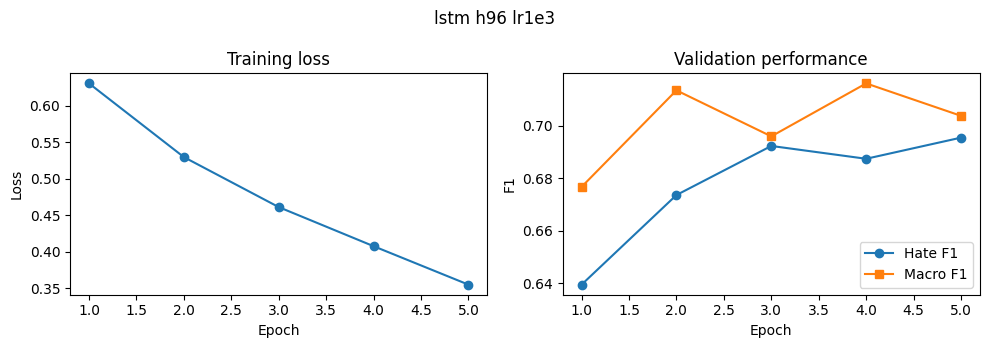

lstm_h128_lr7e4 epoch 1:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h128_lr7e4 | epoch 1 | loss=0.6384 | val Hate F1=0.6449


lstm_h128_lr7e4 epoch 2:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h128_lr7e4 | epoch 2 | loss=0.5625 | val Hate F1=0.6596


lstm_h128_lr7e4 epoch 3:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h128_lr7e4 | epoch 3 | loss=0.5136 | val Hate F1=0.6416


lstm_h128_lr7e4 epoch 4:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h128_lr7e4 | epoch 4 | loss=0.4712 | val Hate F1=0.6653


lstm_h128_lr7e4 epoch 5:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_h128_lr7e4 | epoch 5 | loss=0.4378 | val Hate F1=0.6763


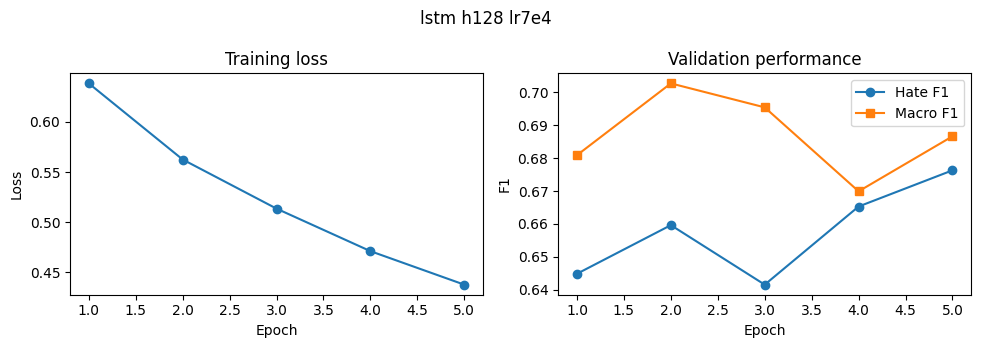

LSTM full-text best: {'score': 0.6954732510288066, 'config': {'name': 'lstm_h96_lr1e3', 'emb_dim': 128, 'hidden_dim': 96, 'dropout': 0.3, 'lr': 0.001, 'batch_size': 64, 'epochs': 5}, 'variant': 'full', 'trial': 'lstm_h96_lr1e3'}


In [ ]:
@torch.no_grad()
def evaluate_lstm(model, loader):
    model.eval()
    all_y, all_p = [], []
    for ids, lengths, labels in loader:
        logits = model(ids.to(device), lengths.to(device))
        probs = torch.softmax(logits, dim=-1)[:,1]
        all_y.extend(labels.numpy().tolist())
        all_p.extend(probs.detach().cpu().numpy().tolist())
    return np.array(all_y), np.array(all_p)

def fit_lstm(cfg, variant, trial_name):
    tr_loader, va_loader = lstm_loaders(variant, batch_size=cfg['batch_size'])
    model = BiLSTMClassifier(
        len(stoi), emb_dim=cfg['emb_dim'], hidden_dim=cfg['hidden_dim'],
        dropout=cfg['dropout']
    ).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    history, best_f1, stale = [], -1.0, 0
    trial_ckpt = MODEL_DIR / f'{trial_name}_temporary.pt'

    for ep in range(1, cfg['epochs']+1):
        model.train()
        total, seen = 0.0, 0
        for ids, lengths, labels in tqdm(tr_loader, desc=f'{trial_name} epoch {ep}', leave=False):
            ids, lengths, labels = ids.to(device), lengths.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids, lengths)
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total += loss.item() * len(labels)
            seen += len(labels)
        y, p = evaluate_lstm(model, va_loader)
        metrics = compute_metrics(y,p)
        history.append({'epoch':ep, 'train_loss':total/max(seen,1),
                        'val_f1_hate':metrics['f1_hate'], 'val_f1_macro':metrics['f1_macro'],
                        'val_accuracy':metrics['accuracy']})
        print(f'{trial_name} | epoch {ep} | loss={total/max(seen,1):.4f} | val Hate F1={metrics["f1_hate"]:.4f}')
        if metrics['f1_hate'] > best_f1 + 1e-6:
            best_f1 = metrics['f1_hate']
            torch.save(model.state_dict(), trial_ckpt)
            stale = 0
        else:
            stale += 1
            if stale >= 2:
                print('Early stopping (2 consecutive non-improving epochs)')
                break

    model.load_state_dict(torch.load(trial_ckpt, map_location='cpu', weights_only=True))
    model.to(device)
    y, p = evaluate_lstm(model, va_loader)
    final_val_metrics = compute_metrics(y,p)
    del model, optimizer, tr_loader, va_loader
    gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()
    return history, final_val_metrics, trial_ckpt

LSTM_TRIALS = [
    {'name':'lstm_h96_lr1e3', 'emb_dim':128, 'hidden_dim':96,
     'dropout':0.3, 'lr':1e-3, 'batch_size':64, 'epochs':5},
    {'name':'lstm_h128_lr7e4', 'emb_dim':128, 'hidden_dim':128,
     'dropout':0.4, 'lr':7e-4, 'batch_size':64, 'epochs':5},
]
lstm_trials = []
best_lstm = {'score':-1.0}
LSTM_BEST_PATH = MODEL_DIR / 'best_lstm_weights.pt'

def record_lstm_trial(cfg, variant, trial_name):
    global best_lstm
    hist, val_metrics, tmp_file = fit_lstm(cfg, variant, trial_name)
    show_history(hist, trial_name)
    row = {'model':'LSTM', 'trial':trial_name, 'variant':variant,
           'hidden_dim':cfg['hidden_dim'], 'dropout':cfg['dropout'], 'lr':cfg['lr'],
           'selected_terms': N_FEATURES if variant == 'full' else len(selected_word_sets[variant]),
           **val_metrics}
    lstm_trials.append(row)
    if val_metrics['f1_hate'] > best_lstm['score']:
        shutil.copy2(tmp_file, LSTM_BEST_PATH)
        best_lstm = {'score':val_metrics['f1_hate'], 'config':cfg.copy(),
                     'variant':variant, 'trial':trial_name}
    tmp_file.unlink(missing_ok=True)
    return row

for cfg in LSTM_TRIALS:
    record_lstm_trial(cfg, 'full', cfg['name'])
print('LSTM full-text best:', best_lstm)

## 6. LSTM feature-selection experiments | Person 1
The best LSTM hyperparameters from full text are used to train the **top-half** and **top-quarter** lexical-feature variants. The held-out test remains unused. Outputs automatically support your report's feature-selection subsection.

lstm_features_top_half epoch 1:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_half | epoch 1 | loss=0.6120 | val Hate F1=0.6545


lstm_features_top_half epoch 2:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_half | epoch 2 | loss=0.5121 | val Hate F1=0.6777


lstm_features_top_half epoch 3:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_half | epoch 3 | loss=0.4586 | val Hate F1=0.6835


lstm_features_top_half epoch 4:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_half | epoch 4 | loss=0.4127 | val Hate F1=0.6886


lstm_features_top_half epoch 5:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_half | epoch 5 | loss=0.3762 | val Hate F1=0.6845


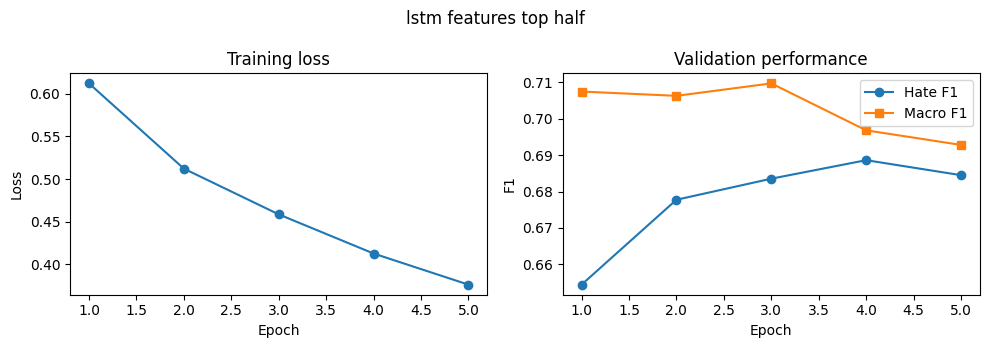

lstm_features_top_quarter epoch 1:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_quarter | epoch 1 | loss=0.6043 | val Hate F1=0.6688


lstm_features_top_quarter epoch 2:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_quarter | epoch 2 | loss=0.4946 | val Hate F1=0.6838


lstm_features_top_quarter epoch 3:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_quarter | epoch 3 | loss=0.4470 | val Hate F1=0.6857


lstm_features_top_quarter epoch 4:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_quarter | epoch 4 | loss=0.4131 | val Hate F1=0.6848


lstm_features_top_quarter epoch 5:   0%|          | 0/141 [00:00<?, ?it/s]

lstm_features_top_quarter | epoch 5 | loss=0.3845 | val Hate F1=0.6879


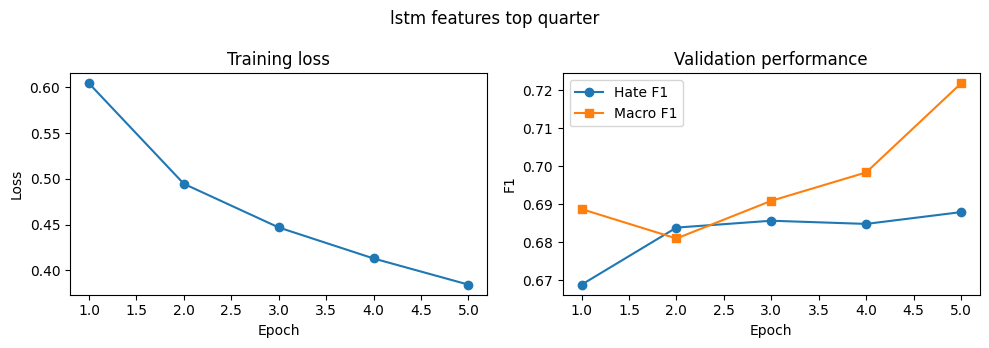

,model,trial,variant,hidden_dim,dropout,lr,selected_terms,accuracy,precision_hate,recall_hate,f1_hate,f1_macro,roc_auc,average_precision
0,LSTM,lstm_h96_lr1e3,full,96,0.3,0.0010,7565,0.704,0.620183,0.791569,0.695473,0.703768,0.800647,0.746207
2,LSTM,lstm_features_top_half,top_half,96,0.3,0.0010,3782,0.697,0.613553,0.784543,0.688592,0.696779,0.797459,0.752869
3,LSTM,lstm_features_top_quarter,top_quarter,96,0.3,0.0010,1891,0.726,0.669623,0.707260,0.687927,0.721860,0.801566,0.764568
1,LSTM,lstm_h128_lr7e4,full,128,0.4,0.0007,7565,0.687,0.605556,0.765808,0.676319,0.686659,0.789685,0.750081


Chosen LSTM (validation only): {'score': 0.6954732510288066, 'config': {'name': 'lstm_h96_lr1e3', 'emb_dim': 128, 'hidden_dim': 96, 'dropout': 0.3, 'lr': 0.001, 'batch_size': 64, 'epochs': 5}, 'variant': 'full', 'trial': 'lstm_h96_lr1e3'}


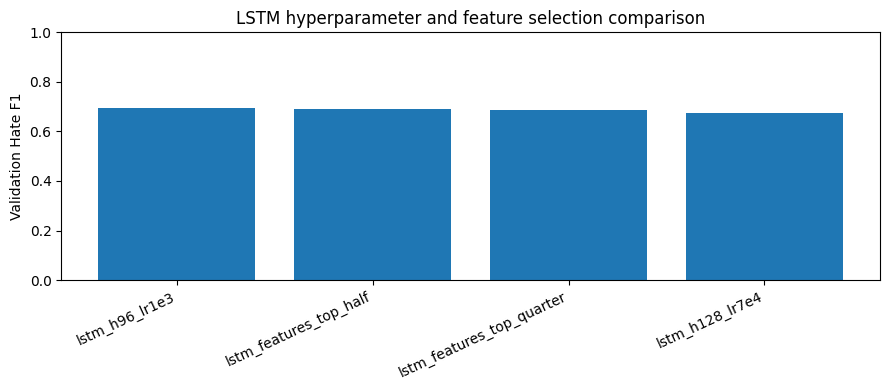

In [ ]:
best_full_lstm_cfg = best_lstm['config'].copy()
if RUN_LSTM_FEATURE_EXPERIMENTS:
    for variant in ['top_half', 'top_quarter']:
        cfg = best_full_lstm_cfg.copy()
        record_lstm_trial(cfg, variant, f'lstm_features_{variant}')

lstm_val_table = pd.DataFrame(lstm_trials).sort_values('f1_hate', ascending=False)
lstm_val_table.to_csv(TABLE_DIR / 'lstm_validation_search.csv', index=False)
display(lstm_val_table)
print('Chosen LSTM (validation only):', best_lstm)

plt.figure(figsize=(9,4))
plt.bar(lstm_val_table.trial, lstm_val_table.f1_hate)
plt.xticks(rotation=25, ha='right')
plt.ylabel('Validation Hate F1')
plt.ylim(0,1)
plt.title('LSTM hyperparameter and feature selection comparison')
plt.tight_layout()
plt.savefig(FIG_DIR / 'lstm_search_comparison.png', dpi=170, bbox_inches='tight')
plt.show()

# Persist a reproducible LSTM checkpoint description.
with open(MODEL_DIR / 'lstm_metadata.json', 'w', encoding='utf-8') as f:
    json.dump({'architecture':'Bidirectional LSTM', 'best':best_lstm,
               'vocab':stoi,'max_length':LSTM_MAX_LEN}, f, ensure_ascii=False, indent=2)

# PERSON 2 | BERT model (Sections 7–9)
This section fine-tunes `bert-base-uncased` for the exact same binary labels. All feature ranking was fitted on the training data in Section 2. **Use a GPU runtime for the BERT experiments.**

## 7. BERT tokenizer and dataloaders
BERT uses its own pretrained WordPiece tokenizer. The lexical-feature experiments optionally feed word-filtered text to the tokenizer. The full-text baseline retains the normal text context.

In [ ]:
BERT_MODEL_NAME = 'bert-base-uncased'
BERT_MAX_LEN = 128
bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME, use_fast=True)

def bert_loaders(variant, batch_size=16):
    def tokenize(frame):
        texts = texts_for_variant(frame, variant)
        enc = bert_tokenizer(
            texts, truncation=True, padding='max_length',
            max_length=BERT_MAX_LEN, return_tensors='pt'
        )
        return TensorDataset(
            enc['input_ids'], enc['attention_mask'],
            torch.tensor(frame.label.to_numpy(dtype=int), dtype=torch.long)
        )
    return (
        DataLoader(tokenize(train_df), batch_size=batch_size, shuffle=True),
        DataLoader(tokenize(val_df), batch_size=batch_size, shuffle=False)
    )

def new_bert():
    return AutoModelForSequenceClassification.from_pretrained(
        BERT_MODEL_NAME, num_labels=2,
        id2label={0:'Non-hate',1:'Hate'},
        label2id={'Non-hate':0,'Hate':1}
    ).to(device)

@torch.no_grad()
def evaluate_bert(model, loader):
    model.eval()
    y_all, p_all = [], []
    for ids, attn_mask, labels in loader:
        logits = model(input_ids=ids.to(device),
                       attention_mask=attn_mask.to(device)).logits
        prob = torch.softmax(logits, dim=-1)[:,1]
        y_all.extend(labels.numpy().tolist())
        p_all.extend(prob.detach().cpu().numpy().tolist())
    return np.asarray(y_all), np.asarray(p_all)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

## 8. BERT fine-tuning and hyperparameter experiments | Person 2
Trials compare two learning rates on **full text**. Each begins with the original pretrained weights (no continued fine-tuning from a previous trial), uses AdamW, warmup, gradient clipping and best-epoch validation checkpointing. This intentionally avoids the version-sensitive `Trainer` API.

I0000 00:00:1794583820.802454      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


bert_lr2e5 epoch 1:   0%|          | 0/563 [00:00<?, ?it/s]

bert_lr2e5 | epoch 1 | loss=0.5081 | val Hate F1=0.7457


bert_lr2e5 epoch 2:   0%|          | 0/563 [00:00<?, ?it/s]

bert_lr2e5 | epoch 2 | loss=0.3197 | val Hate F1=0.7772


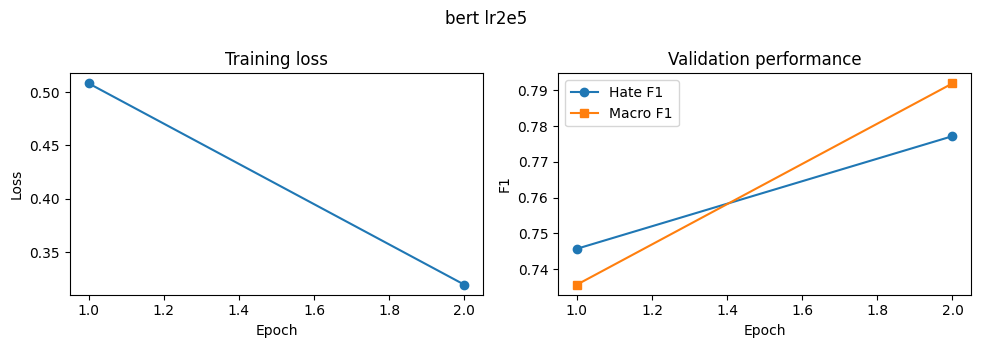

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


bert_lr3e5 epoch 1:   0%|          | 0/563 [00:00<?, ?it/s]

bert_lr3e5 | epoch 1 | loss=0.4880 | val Hate F1=0.7566


bert_lr3e5 epoch 2:   0%|          | 0/563 [00:00<?, ?it/s]

bert_lr3e5 | epoch 2 | loss=0.2986 | val Hate F1=0.7625


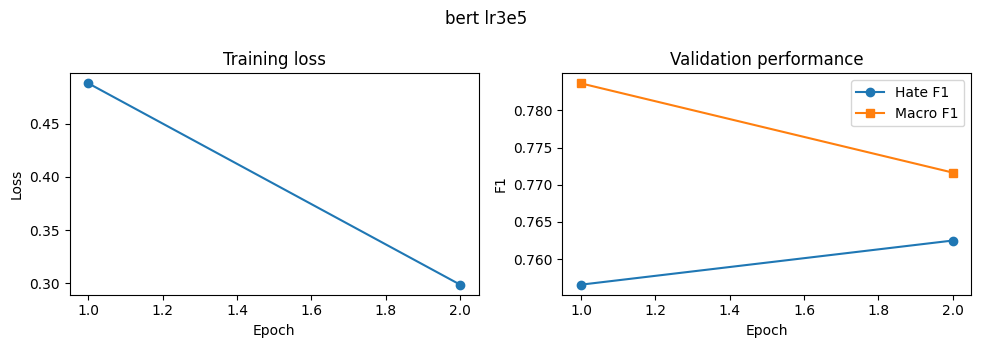

BERT full-text best: {'score': 0.7771797631862217, 'config': {'name': 'bert_lr2e5', 'lr': 2e-05, 'epochs': 2, 'batch_size': 16, 'weight_decay': 0.01}, 'variant': 'full', 'trial': 'bert_lr2e5'}


In [ ]:
def fit_bert(cfg, variant, trial_name):
    tr_loader, va_loader = bert_loaders(variant, batch_size=cfg['batch_size'])
    model = new_bert()
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    total_steps = len(tr_loader)*cfg['epochs']
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=max(1,int(0.1*total_steps)),
        num_training_steps=total_steps
    )
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    hist, best_f1, stale = [], -1.0, 0
    tmp_ckpt = MODEL_DIR / f'{trial_name}_temporary.pt'

    for ep in range(1,cfg['epochs']+1):
        model.train()
        loss_total, seen = 0.0, 0
        for ids, attn, labels in tqdm(tr_loader, desc=f'{trial_name} epoch {ep}', leave=False):
            ids, attn, labels = ids.to(device), attn.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(input_ids=ids, attention_mask=attn).logits
            loss = criterion(logits, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            loss_total += loss.item() * len(labels)
            seen += len(labels)

        y_val, p_val = evaluate_bert(model, va_loader)
        metrics = compute_metrics(y_val,p_val)
        hist.append({'epoch':ep, 'train_loss':loss_total/max(seen,1),
                     'val_f1_hate':metrics['f1_hate'], 'val_f1_macro':metrics['f1_macro'],
                     'val_accuracy':metrics['accuracy']})
        print(f'{trial_name} | epoch {ep} | loss={loss_total/max(seen,1):.4f} | val Hate F1={metrics["f1_hate"]:.4f}')
        if metrics['f1_hate'] > best_f1 + 1e-6:
            best_f1 = metrics['f1_hate']
            torch.save(model.state_dict(), tmp_ckpt)
            stale = 0
        else:
            stale += 1
            if stale >= 2:
                print('Early stopping (2 consecutive non-improving epochs)')
                break

    model.load_state_dict(torch.load(tmp_ckpt, map_location='cpu', weights_only=True))
    model.to(device)
    y_val, p_val = evaluate_bert(model, va_loader)
    val_metrics = compute_metrics(y_val, p_val)
    del model, optimizer, scheduler, tr_loader, va_loader
    gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()
    return hist, val_metrics, tmp_ckpt

BERT_TRIALS = [
    {'name':'bert_lr2e5', 'lr':2e-5, 'epochs':2, 'batch_size':16, 'weight_decay':0.01},
    {'name':'bert_lr3e5', 'lr':3e-5, 'epochs':2, 'batch_size':16, 'weight_decay':0.01},
]
bert_trials = []
best_bert = {'score':-1.0}
BERT_BEST_PATH = MODEL_DIR / 'best_bert_weights.pt'

def record_bert_trial(cfg, variant, trial_name):
    global best_bert
    hist, val_metrics, tmp_file = fit_bert(cfg, variant, trial_name)
    show_history(hist, trial_name)
    row = {'model':'BERT', 'trial':trial_name, 'variant':variant,
           'lr':cfg['lr'], 'batch_size':cfg['batch_size'], 'epochs':cfg['epochs'],
           'selected_terms':N_FEATURES if variant == 'full' else len(selected_word_sets[variant]),
           **val_metrics}
    bert_trials.append(row)
    if val_metrics['f1_hate'] > best_bert['score']:
        shutil.copy2(tmp_file, BERT_BEST_PATH)
        best_bert = {'score':val_metrics['f1_hate'], 'config':cfg.copy(),
                     'variant':variant, 'trial':trial_name}
    tmp_file.unlink(missing_ok=True)
    return row

for cfg in BERT_TRIALS:
    record_bert_trial(cfg, 'full', cfg['name'])
print('BERT full-text best:', best_bert)

## 9. BERT feature-selection ablation | Person 2
Apply the **same train-only ranked top-half and top-quarter lexical subsets** used for LSTM, retraining BERT with the best full-text learning rate. These ablations test whether reducing vocabulary-related content helps or hurts. A top-word filter is not guaranteed to preserve grammatical context, so interpret these results cautiously.

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


bert_features_top_half epoch 1:   0%|          | 0/563 [00:00<?, ?it/s]

bert_features_top_half | epoch 1 | loss=0.5011 | val Hate F1=0.6946


bert_features_top_half epoch 2:   0%|          | 0/563 [00:00<?, ?it/s]

bert_features_top_half | epoch 2 | loss=0.3418 | val Hate F1=0.7443


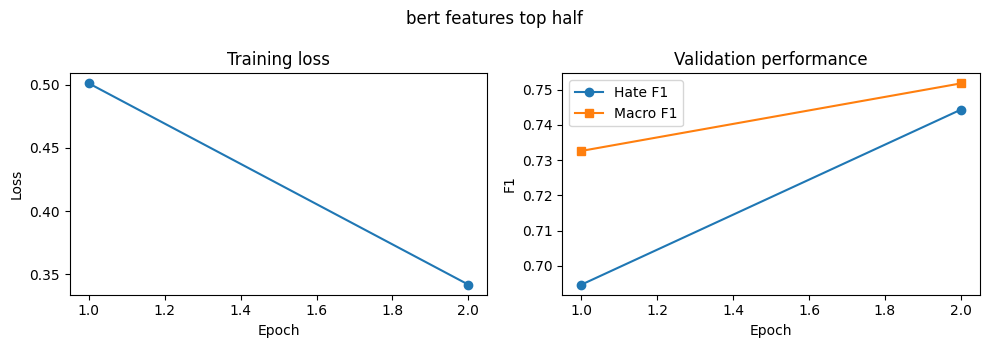

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


bert_features_top_quarter epoch 1:   0%|          | 0/563 [00:00<?, ?it/s]

bert_features_top_quarter | epoch 1 | loss=0.5174 | val Hate F1=0.6959


bert_features_top_quarter epoch 2:   0%|          | 0/563 [00:00<?, ?it/s]

bert_features_top_quarter | epoch 2 | loss=0.3604 | val Hate F1=0.7034


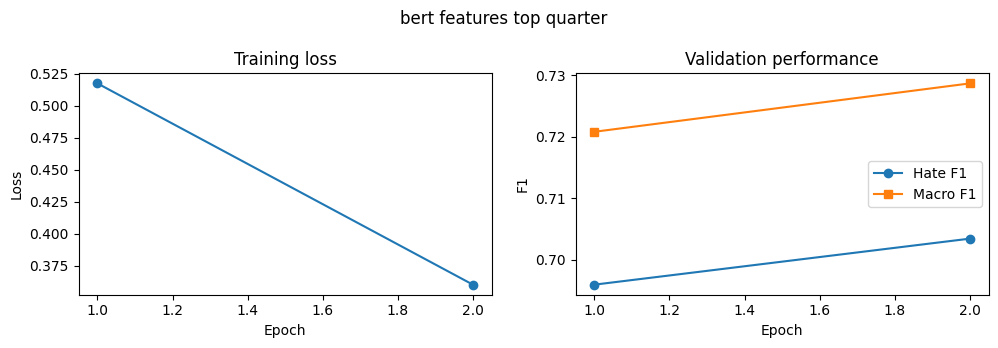

,model,trial,variant,lr,batch_size,epochs,selected_terms,accuracy,precision_hate,recall_hate,f1_hate,f1_macro,roc_auc,average_precision
0,BERT,bert_lr2e5,full,0.00002,16,2,7565,0.793,0.719124,0.845433,0.777180,0.791951,0.871869,0.831741
1,BERT,bert_lr3e5,full,0.00003,16,2,7565,0.772,0.686679,0.857143,0.762500,0.771635,0.874779,0.837090
2,BERT,bert_features_top_half,top_half,0.00002,16,2,3782,0.752,0.664825,0.845433,0.744330,0.751777,0.847898,0.800275
3,BERT,bert_features_top_quarter,top_quarter,0.00002,16,2,1891,0.731,0.664583,0.747073,0.703418,0.728653,0.813934,0.767135


Chosen BERT (validation only): {'score': 0.7771797631862217, 'config': {'name': 'bert_lr2e5', 'lr': 2e-05, 'epochs': 2, 'batch_size': 16, 'weight_decay': 0.01}, 'variant': 'full', 'trial': 'bert_lr2e5'}


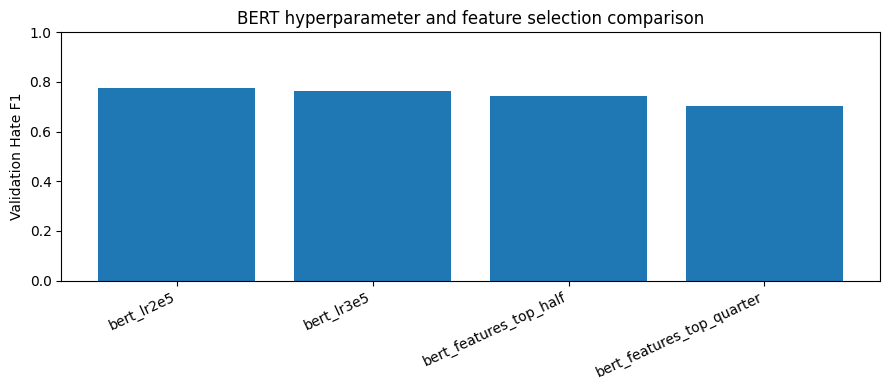

In [ ]:
best_full_bert_cfg = best_bert['config'].copy()
if RUN_BERT_FEATURE_EXPERIMENTS:
    for variant in ['top_half', 'top_quarter']:
        cfg = best_full_bert_cfg.copy()
        record_bert_trial(cfg, variant, f'bert_features_{variant}')

bert_val_table = pd.DataFrame(bert_trials).sort_values('f1_hate', ascending=False)
bert_val_table.to_csv(TABLE_DIR / 'bert_validation_search.csv', index=False)
display(bert_val_table)
print('Chosen BERT (validation only):', best_bert)

plt.figure(figsize=(9,4))
plt.bar(bert_val_table.trial, bert_val_table.f1_hate)
plt.xticks(rotation=25, ha='right')
plt.ylabel('Validation Hate F1')
plt.ylim(0,1)
plt.title('BERT hyperparameter and feature selection comparison')
plt.tight_layout()
plt.savefig(FIG_DIR / 'bert_search_comparison.png', dpi=170, bbox_inches='tight')
plt.show()

with open(MODEL_DIR / 'bert_metadata.json', 'w', encoding='utf-8') as f:
    json.dump({'pretrained_model':BERT_MODEL_NAME, 'best':best_bert,
               'max_length':BERT_MAX_LEN,
               'feature_selection':'train-only chi-squared word filtering'}, f, indent=2)

# SHARED | Final evaluation, comparison, and demo (Sections 10–13)
Run this section **only after** all intended validation-based tuning and selection experiments have finished. Both selected checkpoints are evaluated on the **same original held-out TweetEval test split**. This is the **first time** the test labels are used to measure model performance.

## 10. Reload selected LSTM and BERT checkpoints

In [ ]:
chosen_lstm_cfg = best_lstm['config']
lstm_final = BiLSTMClassifier(
    len(stoi), emb_dim=chosen_lstm_cfg['emb_dim'],
    hidden_dim=chosen_lstm_cfg['hidden_dim'],
    dropout=chosen_lstm_cfg['dropout']
)
lstm_final.load_state_dict(torch.load(LSTM_BEST_PATH, map_location='cpu', weights_only=True))
lstm_final.to(device).eval()

# Free any abandoned GPU memory before loading the selected BERT model.
gc.collect()
if device.type == 'cuda': torch.cuda.empty_cache()
bert_final = new_bert()
bert_final.load_state_dict(torch.load(BERT_BEST_PATH, map_location='cpu', weights_only=True))
bert_final.eval()

# Save a standard HF directory to make BERT reusable later.
bert_export = MODEL_DIR / 'selected_bert_hf'
bert_final.save_pretrained(bert_export, safe_serialization=True)
bert_tokenizer.save_pretrained(bert_export)
print('Selected checkpoints loaded successfully.')

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Selected checkpoints loaded successfully.


## 11. Held-out test evaluation | Results Section 6.2
All test predictions are generated exactly once per selected model. If you later decide to modify hyperparameters based on these results, that would contaminate the held-out comparison and must be disclosed or evaluated with a new unseen test set.

,Model,Best_trial,Selected_features,accuracy,precision_hate,recall_hate,f1_hate,f1_macro,roc_auc,average_precision
0,LSTM,lstm_h96_lr1e3,full,0.4596,0.4355,0.9521,0.5976,0.3875,0.5893,0.4842
1,BERT,bert_lr2e5,full,0.5219,0.4677,0.9720,0.6316,0.4754,0.6338,0.4737


Selected LSTM | Test results


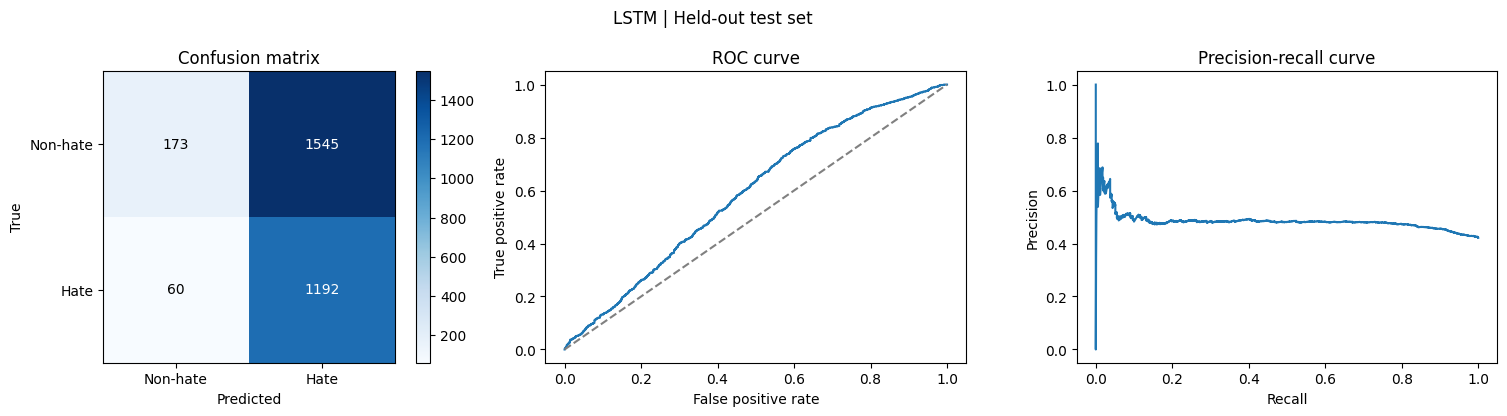

              precision    recall  f1-score   support

    Non-hate       0.74      0.10      0.18      1718
        Hate       0.44      0.95      0.60      1252

    accuracy                           0.46      2970
   macro avg       0.59      0.53      0.39      2970
weighted avg       0.61      0.46      0.35      2970

Selected BERT | Test results


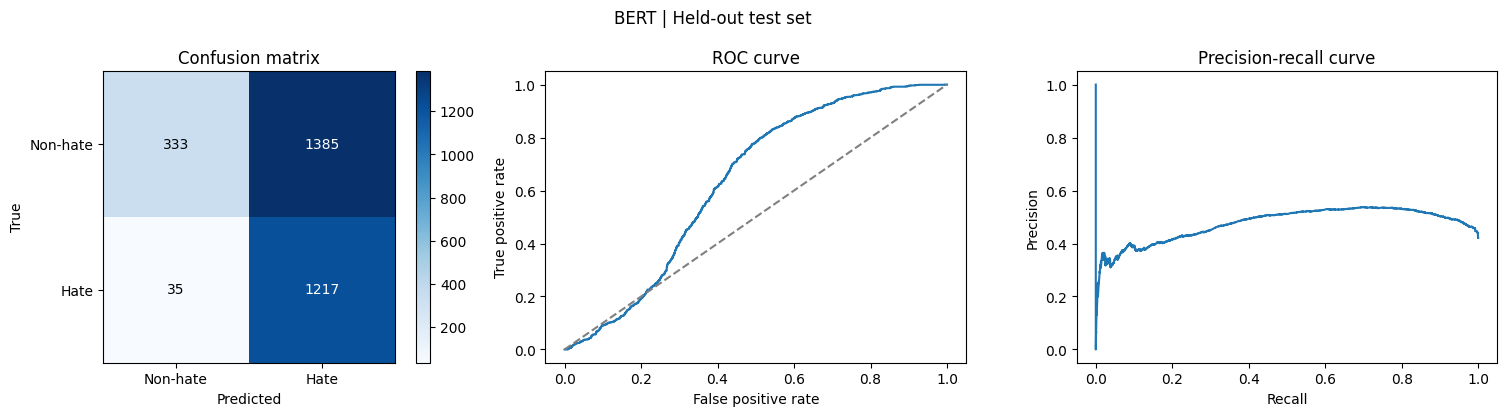

              precision    recall  f1-score   support

    Non-hate       0.90      0.19      0.32      1718
        Hate       0.47      0.97      0.63      1252

    accuracy                           0.52      2970
   macro avg       0.69      0.58      0.48      2970
weighted avg       0.72      0.52      0.45      2970



In [ ]:
# Person 1: selected LSTM evaluated once on test.
lstm_test_ds = TextLSTMDataset(
    texts_for_variant(test_df, best_lstm['variant']), test_df.label.to_numpy()
)
lstm_test_loader = DataLoader(lstm_test_ds, batch_size=64, shuffle=False)
y_lstm, p_lstm = evaluate_lstm(lstm_final, lstm_test_loader)
lstm_test_metrics = compute_metrics(y_lstm, p_lstm)

# Person 2: selected BERT evaluated once on the same test labels.
bert_test_texts = texts_for_variant(test_df, best_bert['variant'])
bert_test_enc = bert_tokenizer(
    bert_test_texts, truncation=True, padding='max_length',
    max_length=BERT_MAX_LEN, return_tensors='pt'
)
bert_test_ds = TensorDataset(
    bert_test_enc['input_ids'], bert_test_enc['attention_mask'],
    torch.tensor(test_df.label.to_numpy(dtype=int), dtype=torch.long)
)
bert_test_loader = DataLoader(bert_test_ds, batch_size=16, shuffle=False)
y_bert, p_bert = evaluate_bert(bert_final, bert_test_loader)
assert np.array_equal(y_lstm, y_bert), 'Test order changed between models'

bert_test_metrics = compute_metrics(y_bert, p_bert)
comparison = pd.DataFrame([
    {'Model':'LSTM', 'Best_trial':best_lstm['trial'],
     'Selected_features':best_lstm['variant'], **lstm_test_metrics},
    {'Model':'BERT', 'Best_trial':best_bert['trial'],
     'Selected_features':best_bert['variant'], **bert_test_metrics}
]).round(4)
comparison.to_csv(TABLE_DIR / 'FINAL_HELD_OUT_TEST_COMPARISON.csv', index=False)
display(comparison)

print('Selected LSTM | Test results')
draw_final_plots(y_lstm, p_lstm, 'LSTM')
print('Selected BERT | Test results')
draw_final_plots(y_bert, p_bert, 'BERT')

results_detail = pd.DataFrame({
    'true_label': y_lstm,
    'lstm_prob_hate': p_lstm, 'lstm_pred': (p_lstm >= 0.5).astype(int),
    'bert_prob_hate': p_bert, 'bert_pred': (p_bert >= 0.5).astype(int)
})
results_detail.to_csv(TABLE_DIR / 'test_predictions_numeric_only.csv', index=False)

## 12. Model comparison charts, feature-selection table, and error analysis | Shared
For the report, use test metrics **only** for the selected final models. Feature-selection/hyperparameter tables use **validation** metrics. Also discuss false positives and false negatives, model limitations, and any dataset duplicates found in Section 1.

,model,trial,variant,selected_terms,f1_hate,f1_macro,accuracy
0,LSTM,lstm_h96_lr1e3,full,7565,0.695473,0.703768,0.704
1,LSTM,lstm_h128_lr7e4,full,7565,0.676319,0.686659,0.687
2,LSTM,lstm_features_top_half,top_half,3782,0.688592,0.696779,0.697
3,LSTM,lstm_features_top_quarter,top_quarter,1891,0.687927,0.721860,0.726
4,BERT,bert_lr2e5,full,7565,0.777180,0.791951,0.793
5,BERT,bert_lr3e5,full,7565,0.762500,0.771635,0.772
6,BERT,bert_features_top_half,top_half,3782,0.744330,0.751777,0.752
7,BERT,bert_features_top_quarter,top_quarter,1891,0.703418,0.728653,0.731


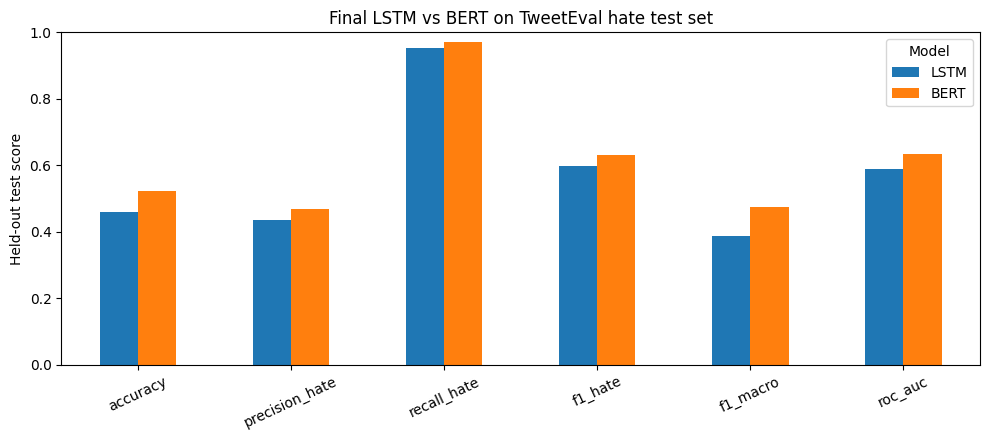

,Model,Total errors,False positives,False negatives,Error rate
0,LSTM,1605,1545,60,0.540404
1,BERT,1420,1385,35,0.478114


In [ ]:
# Report template 6.1: for each model, compare full/half/quarter on VALIDATION.
feature_selection_table = pd.concat([
    pd.DataFrame(lstm_trials)[['model','trial','variant','selected_terms','f1_hate','f1_macro','accuracy']],
    pd.DataFrame(bert_trials)[['model','trial','variant','selected_terms','f1_hate','f1_macro','accuracy']],
], ignore_index=True)
feature_selection_table.to_csv(TABLE_DIR / 'FEATURE_SELECTION_VALIDATION_RESULTS.csv', index=False)
display(feature_selection_table)

# Final test comparison plot.
metrics_to_show = ['accuracy','precision_hate','recall_hate','f1_hate','f1_macro','roc_auc']
compare_plot = comparison.set_index('Model')[metrics_to_show].T
ax = compare_plot.plot(kind='bar', figsize=(10,4.5), ylim=(0,1), rot=25)
ax.set_ylabel('Held-out test score')
ax.set_title('Final LSTM vs BERT on TweetEval hate test set')
plt.tight_layout()
plt.savefig(FIG_DIR / 'final_models_comparison.png', dpi=170, bbox_inches='tight')
plt.show()

# Error analysis: show INDICES and AGGREGATE metrics without automatically displaying harmful text.
error_rows = []
for name, probs in [('LSTM',p_lstm), ('BERT',p_bert)]:
    pred = (probs >= 0.5).astype(int)
    errors = np.where(pred != y_lstm)[0]
    fp = int(np.sum((pred == 1) & (y_lstm == 0)))
    fn = int(np.sum((pred == 0) & (y_lstm == 1)))
    error_rows.append({'Model':name, 'Total errors':len(errors), 'False positives':fp,
                       'False negatives':fn, 'Error rate':len(errors)/len(y_lstm)})
error_analysis = pd.DataFrame(error_rows)
error_analysis.to_csv(TABLE_DIR / 'error_analysis_summary.csv', index=False)
display(error_analysis)

# For human-reviewed qualitative examples, inspect test_df.iloc[index].text manually.
# Do not copy raw hateful or private text unnecessarily into your report or demo.

## 13. Final demo | Both models on an input message
The demo reports *model predictions*, not proven facts about whether a message is hateful. Use for research demonstration or human review, not automated disciplinary decisions.

In [ ]:
@torch.no_grad()
def predict_message(message):
    original = clean_text(message)

    lstm_input = filter_selected_words(original, selected_word_sets[best_lstm['variant']])
    lstm_ids, lstm_length = encode_lstm(lstm_input)
    ids = torch.tensor([lstm_ids], dtype=torch.long, device=device)
    lens = torch.tensor([lstm_length], dtype=torch.long, device=device)
    lstm_final.eval()
    p1 = float(torch.softmax(lstm_final(ids, lens), dim=-1)[0,1].cpu())

    bert_input = filter_selected_words(original, selected_word_sets[best_bert['variant']])
    benc = bert_tokenizer(
        bert_input, truncation=True, padding='max_length',
        max_length=BERT_MAX_LEN, return_tensors='pt'
    )
    bert_final.eval()
    logits = bert_final(
        input_ids=benc['input_ids'].to(device),
        attention_mask=benc['attention_mask'].to(device)
    ).logits
    p2 = float(torch.softmax(logits, dim=-1)[0,1].cpu())

    return pd.DataFrame([
        {'Model':'LSTM', 'Predicted label':LABEL_NAMES[int(p1 >= 0.5)],
         'P(Hate)':round(p1,4), 'Decision threshold':0.5},
        {'Model':'BERT', 'Predicted label':LABEL_NAMES[int(p2 >= 0.5)],
         'P(Hate)':round(p2,4), 'Decision threshold':0.5},
    ])

# Non-hateful demonstration text; substitute other inputs for your presentation.
sample_message = 'Thank you for sharing your opinion. I disagree, but I respect your view.'
display(predict_message(sample_message))

,Model,Predicted label,P(Hate),Decision threshold
0,LSTM,Non-hate,0.1459,0.5
1,BERT,Non-hate,0.0200,0.5


## 14. Export report files and trained models (Kaggle)

- **`/kaggle/working/ARTI502_Topic6_Outputs/`** contains CSV tables, PNG figures, selected model checkpoints, metadata, and the Hugging Face-formatted BERT model directory.
- The **report ZIP** contains only non-weight figures/tables, so it downloads quickly.
- A **separate checkpoint ZIP** contains weights, tokenizer files, and metadata. It may be large; download it or use **Save Version → Output** to retain it.
- Kaggle may reclaim session disk/files when the session ends. Preserve both outputs before disconnecting.
- **Do not publish the notebook publicly without checking course rules and reviewing model artifacts/data.**

In [ ]:
# Export a compact report ZIP (tables + plots) and a separate models ZIP.
report_export = OUTPUT_DIR / 'report_ready_export'
if report_export.exists():
    shutil.rmtree(report_export)
(report_export / 'tables').mkdir(parents=True)
(report_export / 'figures').mkdir(parents=True)
for p in TABLE_DIR.glob('*.csv'):
    shutil.copy2(p, report_export / 'tables' / p.name)
for p in FIG_DIR.glob('*.png'):
    shutil.copy2(p, report_export / 'figures' / p.name)

readme_text = """ARTI 502 Topic 6 - Kaggle report-ready experiment outputs
Dataset: TweetEval hate (full train=9000, validation=1000, test=2970).
Positive class: hate=1. Model selection uses validation hate-class F1.
Hyperparameter and feature-selection comparisons: VALIDATION results only.
Final selected-model evaluation: held-out TEST results.
The notebook must actually be run to obtain real experimental scores.
"""
(report_export / 'README.txt').write_text(readme_text, encoding='utf-8')
report_archive = shutil.make_archive(
    str(OUTPUT_DIR / 'ARTI502_Topic6_report_outputs'), 'zip', root_dir=report_export
)
print('Report ZIP:', report_archive)

# Selected weights + tokenizer + metadata. This can be substantially larger than report ZIP.
checkpoint_archive = shutil.make_archive(
    str(OUTPUT_DIR / 'ARTI502_Topic6_selected_models'), 'zip', root_dir=MODEL_DIR
)
print('Models ZIP:', checkpoint_archive)
print('Kaggle Output directory:', OUTPUT_DIR)
print('Open Kaggle right-side Output panel to download, and Save Version to preserve files.')

Report ZIP: /kaggle/working/ARTI502_Topic6_Outputs/ARTI502_Topic6_report_outputs.zip
Models ZIP: /kaggle/working/ARTI502_Topic6_Outputs/ARTI502_Topic6_selected_models.zip
Kaggle Output directory: /kaggle/working/ARTI502_Topic6_Outputs
Open Kaggle right-side Output panel to download, and Save Version to preserve files.


## 15. Copy-ready reporting checklist (complete after an actual run)
| Report section | Evidence generated by this notebook |
|---|---|
| 5.1 Dataset | `dataset_splits.csv`, TweetEval dataset card and original publication |
| 5.1.1 Statistical analysis | `dataset_text_statistics.csv`, `01_dataset_overview.png` |
| 5.2 Experimental setup | official splits, preprocessing, LSTM and BERT architectures, training-only feature-ranking method |
| 5.3 Performance measures | `compute_metrics`, fixed 0.50 threshold, confusion matrices, ROC and PR curves |
| 5.4 Optimization strategy | `lstm_validation_search.csv`, `bert_validation_search.csv`, per-trial training curves |
| 6.1 Feature-selection results | `FEATURE_SELECTION_VALIDATION_RESULTS.csv`, chi-squared word ranking and subset sizes |
| 6.2 Final results | `FINAL_HELD_OUT_TEST_COMPARISON.csv`, final test plots, final comparison chart |
| 6.3 Prior literature | **To be written from actual published studies**; do not invent comparisons |
| 6.4 Alignment with requirements | English tweet hate/non-hate classification using both BERT and LSTM; limitations acknowledged |

**Study limitations:** Scope is hate speech, not all toxicity; English tweets may not generalize to Reddit/Arabic/other domains; data may contain class bias, duplicates and ambiguous labels. The dataset's official test split is not a substitute for independent external validation. A short student project prototype should not be represented as a production-ready moderation system. Threshold 0.50 is a methodological default, not a calibrated guarantee.

**Publication citation:** Barbieri et al. (2020), *TweetEval: Unified Benchmark and Comparative Evaluation for Tweet Classification*, Findings of EMNLP. Verify academic citations and compare only compatible benchmark splits/metrics when drafting the literature review.

## 16.POST-RUN ADD-ON | Diagnostic review and validation-only improvement


these extra cells do not retrain either model or replace original files. These are exploratory analyses after the original held-out test has already been viewed. Never use test scores to choose thresholds or retrain. The threshold is chosen on one validation half and checked on the other. Any repeat evaluation on the previously inspected test set must be described as post-hoc exploratory, not as a fresh unbiased final test.

In [ ]:
# 16A. Re-run VALIDATION inference with the existing, already-trained models.
# Requires the original notebook's variables and functions in the current Kaggle session.
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import shutil

required = ['val_df','train_df','test_df','lstm_final','bert_final',
            'evaluate_lstm','evaluate_bert','TextLSTMDataset','texts_for_variant',
            'best_lstm','best_bert','bert_tokenizer','BERT_MAX_LEN',
            'compute_metrics','OUTPUT_DIR','device','torch','DataLoader','TensorDataset']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError('Original notebook session not ready; missing: ' + ', '.join(missing) +
                       '. Return to the finished Kaggle session; do NOT rerun training to fix this.')

DIAG_DIR = Path(OUTPUT_DIR) / 'post_run_diagnostics'
DIAG_DIR.mkdir(parents=True, exist_ok=True)

lstm_val_ds = TextLSTMDataset(texts_for_variant(val_df, best_lstm['variant']),
                               val_df.label.to_numpy())
lstm_val_loader = DataLoader(lstm_val_ds, batch_size=64, shuffle=False)
yvl, pvl = evaluate_lstm(lstm_final, lstm_val_loader)

vtexts = texts_for_variant(val_df, best_bert['variant'])
venc = bert_tokenizer(vtexts, truncation=True, padding='max_length',
                      max_length=BERT_MAX_LEN, return_tensors='pt')
bert_val_ds = TensorDataset(venc['input_ids'], venc['attention_mask'],
                            torch.tensor(val_df.label.to_numpy(dtype=int), dtype=torch.long))
yvb, pvb = evaluate_bert(bert_final, DataLoader(bert_val_ds, batch_size=16, shuffle=False))
assert np.array_equal(yvl, yvb) and np.array_equal(yvb, val_df.label.to_numpy())
print('Validation predictions ready:', len(yvl))
for name, prob in [('LSTM',pvl),('BERT',pvb)]:
    print(name, 'original validation:',
          {k:round(v,4) for k,v in compute_metrics(yvl,prob).items()})


Validation predictions ready: 1000
LSTM original validation: {'accuracy': 0.704, 'precision_hate': 0.6202, 'recall_hate': 0.7916, 'f1_hate': 0.6955, 'f1_macro': 0.7038, 'roc_auc': 0.8006, 'average_precision': 0.7462}
BERT original validation: {'accuracy': 0.793, 'precision_hate': 0.7191, 'recall_hate': 0.8454, 'f1_hate': 0.7772, 'f1_macro': 0.792, 'roc_auc': 0.8719, 'average_precision': 0.8317}


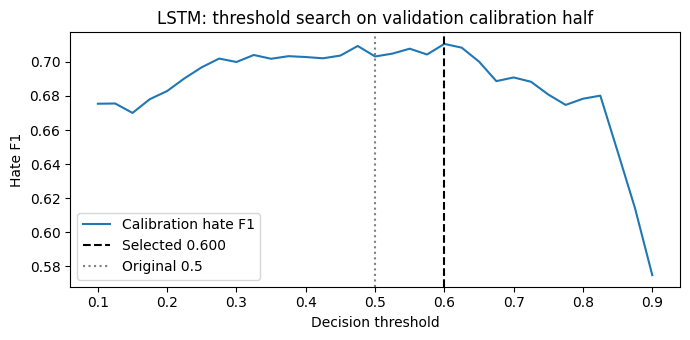

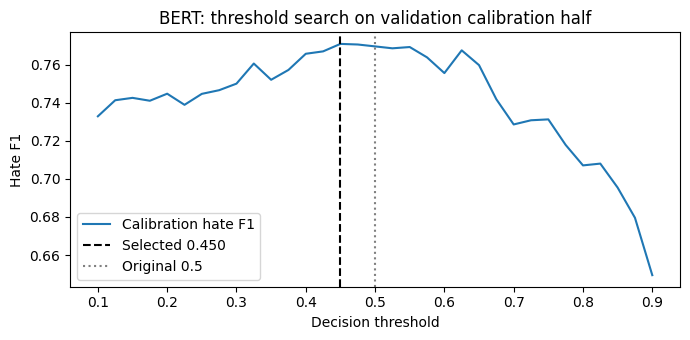

,model,subset,threshold,accuracy,precision_hate,recall_hate,f1_hate,f1_macro,roc_auc
0,LSTM,"Calibration, original",0.50,0.708,0.6201,0.8122,0.7033,0.7079,0.8042
1,LSTM,"Calibration, selected",0.60,0.728,0.6498,0.7840,0.7106,0.7270,0.8042
2,LSTM,"Validation check, original",0.50,0.700,0.6203,0.7710,0.6875,0.6995,0.7964
3,LSTM,"Validation check, selected",0.60,0.720,0.6555,0.7290,0.6903,0.7174,0.7964
4,BERT,"Calibration, original",0.50,0.788,0.7166,0.8310,0.7696,0.7866,0.8606
5,BERT,"Calibration, selected",0.45,0.786,0.7087,0.8451,0.7709,0.7851,0.8606
6,BERT,"Validation check, original",0.50,0.798,0.7216,0.8598,0.7846,0.7972,0.8830
7,BERT,"Validation check, selected",0.45,0.796,0.7154,0.8692,0.7848,0.7954,0.8830


Selected thresholds based ONLY on validation calibration half: {'LSTM': 0.6, 'BERT': 0.45}
IMPORTANT: compare the two Validation check rows before claiming improvement.


In [ ]:
# 16B. Threshold calibration using VALIDATION ONLY.
# Split validation in two stratified halves; choose threshold on calibration half,
# then report its performance on the other half (not on test).
idx = np.arange(len(yvl))
cal_idx, check_idx = train_test_split(idx, test_size=0.5, stratify=yvl,
                                     random_state=2026)
threshold_grid = np.round(np.arange(0.10, 0.901, 0.025), 3)
rows=[]; chosen={}
for name, prob in [('LSTM',pvl),('BERT',pvb)]:
    candidates = []
    for t in threshold_grid:
        m=compute_metrics(yvl[cal_idx],prob[cal_idx],threshold=float(t))
        candidates.append({'threshold':float(t), **m})
    # Select by calibration positive-class F1; break ties by macro F1,
    # then closest to 0.5. This is specified without consulting test labels.
    best=max(candidates,key=lambda r:(r['f1_hate'],r['f1_macro'], -abs(r['threshold']-0.5)))
    selected=best['threshold']; chosen[name]=selected
    for phase, sel, threshold in [('Calibration, original',cal_idx,0.5),
                                   ('Calibration, selected',cal_idx,selected),
                                   ('Validation check, original',check_idx,0.5),
                                   ('Validation check, selected',check_idx,selected)]:
        m=compute_metrics(yvl[sel],prob[sel],threshold=threshold)
        rows.append({'model':name,'subset':phase,'threshold':threshold, **m})
    plt.figure(figsize=(7,3.5))
    plt.plot([r['threshold'] for r in candidates], [r['f1_hate'] for r in candidates],label='Calibration hate F1')
    plt.axvline(selected, linestyle='--',color='black', label=f'Selected {selected:.3f}')
    plt.axvline(0.5, linestyle=':',color='gray',label='Original 0.5')
    plt.xlabel('Decision threshold'); plt.ylabel('Hate F1')
    plt.title(f'{name}: threshold search on validation calibration half')
    plt.legend(); plt.tight_layout()
    plt.savefig(DIAG_DIR/f'{name.lower()}_validation_threshold_search.png',dpi=150)
    plt.show()
threshold_review=pd.DataFrame(rows)
threshold_review.to_csv(DIAG_DIR/'validation_threshold_review.csv',index=False)
display(threshold_review[['model','subset','threshold','accuracy','precision_hate','recall_hate','f1_hate','f1_macro','roc_auc']].round(4))
print('Selected thresholds based ONLY on validation calibration half:',chosen)
print('IMPORTANT: compare the two Validation check rows before claiming improvement.')


In [ ]:
# 16C. Diagnostic breakdown of ORIGINAL test predictions; NO model tuning here.
# Existing test predictions are already saved from initial final evaluation.
# This section is descriptive only, not used to choose a threshold/model.
from sklearn.metrics import confusion_matrix

original_path=Path(TABLE_DIR)/'test_predictions_numeric_only.csv'
if not original_path.exists():
    raise FileNotFoundError(f'Missing original test prediction table: {original_path}')
pred_df=pd.read_csv(original_path)
assert len(pred_df)==len(test_df), 'Saved prediction rows do not match test rows'

train_raw=set(train_df.text.astype(str))
train_clean=set(train_df.clean_text.astype(str))
raw_overlap=test_df.text.astype(str).isin(train_raw).to_numpy()
clean_overlap=test_df.clean_text.astype(str).isin(train_clean).to_numpy()
true=pred_df.true_label.to_numpy(dtype=int)

stat=[]
for name,col in [('LSTM','lstm_prob_hate'),('BERT','bert_prob_hate')]:
    prob=pred_df[col].to_numpy(dtype=float)
    for group,mask in [('all test',np.ones(len(true),dtype=bool)),
                       ('raw text overlaps train',raw_overlap),
                       ('raw text not in train',~raw_overlap),
                       ('normalized text overlaps train',clean_overlap),
                       ('normalized text not in train',~clean_overlap)]:
        if not mask.any(): continue
        result=compute_metrics(true[mask],prob[mask],threshold=0.5)
        stat.append({'model':name,'group':group,'n':int(mask.sum()),
                     'true_hate_share':float(true[mask].mean()),
                     'predicted_hate_share':float((prob[mask]>=.5).mean()),
                     **result})
summary=pd.DataFrame(stat)
summary.to_csv(DIAG_DIR/'test_overlap_diagnostic_original_threshold.csv',index=False)
display(summary[['model','group','n','true_hate_share','predicted_hate_share',
                 'accuracy','f1_hate','f1_macro','roc_auc']].round(4))

# Safe qualitative review: show row IDs and numerical scores, not hateful text by default.
example_rows=[]
for name,col in [('LSTM','lstm_prob_hate'),('BERT','bert_prob_hate')]:
    prob=pred_df[col].to_numpy(dtype=float); guess=(prob>=0.5).astype(int)
    false_positive=np.where((guess==1)&(true==0))[0]
    false_negative=np.where((guess==0)&(true==1))[0]
    for tag,where in [('FP',false_positive),('FN',false_negative)]:
        for k in where[:10]:
            example_rows.append({'model':name,'test_row_index':int(k),
                                 'error_type':tag,'true_label':int(true[k]),
                                 'prob_hate':round(float(prob[k]),4),
                                 'raw_overlap_train':bool(raw_overlap[k])})
examples=pd.DataFrame(example_rows)
examples.to_csv(DIAG_DIR/'error_example_indices_no_raw_text.csv',index=False)
display(examples)
print('To manually inspect one example: test_df.iloc[ROW_INDEX].text')
print('Do not publish harmful text or personal details without careful review.')


,model,group,n,true_hate_share,predicted_hate_share,accuracy,f1_hate,f1_macro,roc_auc
0,LSTM,all test,2970,0.4215,0.9215,0.4596,0.5976,0.3875,0.5893
1,LSTM,raw text overlaps train,233,0.5880,0.9871,0.6009,0.7466,0.4036,0.6713
2,LSTM,raw text not in train,2737,0.4074,0.9160,0.4476,0.5826,0.3831,0.5766
3,LSTM,normalized text overlaps train,236,0.5890,0.9873,0.6017,0.7473,0.4037,0.6632
4,LSTM,normalized text not in train,2734,0.4071,0.9159,0.4473,0.5823,0.3830,0.5769
5,BERT,all test,2970,0.4215,0.8761,0.5219,0.6316,0.4754,0.6338
6,BERT,raw text overlaps train,233,0.5880,0.9785,0.6094,0.7507,0.4248,0.5204
7,BERT,raw text not in train,2737,0.4074,0.8674,0.5144,0.6191,0.4748,0.6355
8,BERT,normalized text overlaps train,236,0.5890,0.9746,0.6059,0.7480,0.4225,0.5186
9,BERT,normalized text not in train,2734,0.4071,0.8676,0.5146,0.6192,0.4750,0.6358


,model,test_row_index,error_type,true_label,prob_hate,raw_overlap_train
0,LSTM,0,FP,0,0.9995,False
1,LSTM,5,FP,0,0.9553,False
2,LSTM,6,FP,0,0.6679,False
3,LSTM,8,FP,0,0.9921,False
4,LSTM,10,FP,0,0.8159,False
5,LSTM,11,FP,0,0.9798,False
6,LSTM,14,FP,0,0.9900,False
7,LSTM,15,FP,0,0.9596,False
8,LSTM,20,FP,0,0.9866,False
9,LSTM,21,FP,0,0.8800,False


To manually inspect one example: test_df.iloc[ROW_INDEX].text
Do not publish harmful text or personal details without careful review.


In [ ]:
# 16D. Save a SEPARATE lightweight package; do not overwrite original report ZIP.
readme=(
'POST-HOC DIAGNOSTICS / VALIDATION-ONLY THRESHOLD STUDY\n'
'The original held-out test scores were inspected before these analyses.\n'
'Validation is split into 50% calibration and 50% confirmation.\n'
'Test overlap breakdown describes ORIGINAL 0.50-threshold results only;\n'
'it must NOT be used to choose models or decision thresholds.\n'
'Confirmation scores are based on only about 500 examples and may be noisy.\n'
'No new clean held-out test evaluation was conducted.\n'
)
(DIAG_DIR/'README.txt').write_text(readme,encoding='utf-8')
archive=shutil.make_archive(str(Path(OUTPUT_DIR)/'ARTI502_Topic6_post_run_diagnostics'),
                            'zip',root_dir=DIAG_DIR)
print('Download new diagnostics ZIP from Kaggle Output:', archive)
print('Original model checkpoints and original test reports were NOT replaced.')


Download new diagnostics ZIP from Kaggle Output: /kaggle/working/ARTI502_Topic6_Outputs/ARTI502_Topic6_post_run_diagnostics.zip
Original model checkpoints and original test reports were NOT replaced.


## 17 Additional Optimization: BERT Class-Weight Ablation

In [ ]:
# Section 17.1 - Prepare BERT ablation using existing Train/Validation data.
# Requires earlier setup/preprocessing cells through Section 4 (not old training).
import zipfile
required = ['train_df', 'val_df', 'clean_text', 'device']
missing = [x for x in required if x not in globals()]
if missing:
    raise RuntimeError(f'Run the initial setup/preprocessing cells first. Missing: {missing}')
assert device.type == 'cuda', 'Enable Kaggle T4 GPU before training BERT.'
assert len(train_df) == 9000 and len(val_df) == 1000, 'This experiment requires full official splits.'

SEED = 42
BERT_NAME = 'bert-base-uncased'
MAX_LEN, BATCH_SIZE, EPOCHS, LEARNING_RATE, WEIGHT_DECAY = 128, 16, 2, 2e-5, 0.01
RUN_FP_WEIGHTED_EXPERIMENT = False  # Keep off. Only test no-class-weights first.
ROOT = Path('/kaggle/working/ARTI502_Topic6_Outputs/section16_weight_ablation')
ROOT.mkdir(parents=True, exist_ok=True)

def set_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
set_seed()

# Use the same cleaned text as the earlier notebook. No test labels are accessed.
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME, use_fast=True)
def encode16(frame):
    encoded = tokenizer(frame.clean_text.astype(str).tolist(), truncation=True,
        padding='max_length', max_length=MAX_LEN, return_tensors='pt')
    labels = torch.tensor(frame.label.to_numpy(dtype=int), dtype=torch.long)
    return TensorDataset(encoded['input_ids'], encoded['attention_mask'], labels)
train_data = encode16(train_df)
valid_data = encode16(val_df)
print('Ready. Train:',len(train_data),'Validation:',len(valid_data),'Device:',device)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Ready. Train: 9000 Validation: 1000 Device: cuda


In [ ]:
# Evaluation utilities and a full fresh training function.
def metrics_for(y, p):
    pred = (p >= 0.5).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y,pred,average='binary',zero_division=0)
    macro = precision_recall_fscore_support(y,pred,average='macro',zero_division=0)[2]
    tn, fp, fn, tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'accuracy':float(accuracy_score(y,pred)), 'precision_hate':float(pr), 'recall_hate':float(rc),
            'f1_hate':float(f1), 'f1_macro':float(macro), 'roc_auc':float(roc_auc_score(y,p)),
            'false_positives':int(fp),'false_negatives':int(fn), 'predicted_hate_fraction':float(pred.mean())}

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); ys=[]; ps=[]
    for ids, masks, labels in loader:
        logits=model(input_ids=ids.to(device),attention_mask=masks.to(device)).logits
        probs=torch.softmax(logits,dim=1)[:,1]
        ys.extend(labels.numpy().tolist())
        ps.extend(probs.cpu().numpy().tolist())
    return np.array(ys), np.array(ps)

def train_trial(name, weights=None):
    # Fresh initialization on every trial, same 42 seed.
    set_seed()
    generator=torch.Generator().manual_seed(SEED)
    train_loader=DataLoader(train_data,batch_size=BATCH_SIZE,shuffle=True,generator=generator)
    val_loader=DataLoader(valid_data,batch_size=BATCH_SIZE,shuffle=False)
    model=AutoModelForSequenceClassification.from_pretrained(BERT_NAME,num_labels=2,
            id2label={0:'Non-hate',1:'Hate'}, label2id={'Non-hate':0,'Hate':1}).to(device)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    steps=len(train_loader)*EPOCHS
    scheduler=get_linear_schedule_with_warmup(optimizer,num_warmup_steps=max(1,int(.1*steps)),num_training_steps=steps)
    criterion=nn.CrossEntropyLoss(weight=None if weights is None else torch.tensor(weights,dtype=torch.float,device=device))
    histories=[]; best_score=-1; best_file=ROOT/f'{name}_best_state.pt'
    for epoch in range(1,EPOCHS+1):
        model.train(); total_loss=0.0; n=0
        for ids,masks,labels in tqdm(train_loader,desc=f'{name}, epoch {epoch}',leave=False):
            ids,masks,labels=ids.to(device),masks.to(device),labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits=model(input_ids=ids,attention_mask=masks).logits
            loss=criterion(logits,labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step(); scheduler.step()
            total_loss+=loss.item()*labels.shape[0]; n+=labels.shape[0]
        y,p=evaluate(model,val_loader)
        met=metrics_for(y,p)
        print(f'{name}: epoch={epoch} loss={total_loss/n:.4f}, val_hate_f1={met["f1_hate"]:.4f}, val_macro_f1={met["f1_macro"]:.4f}, val_accuracy={met["accuracy"]:.4f}, FP={met["false_positives"]}')
        histories.append({'experiment':name,'epoch':epoch,'train_loss':total_loss/n,**met})
        if met['f1_hate'] > best_score:
            best_score=met['f1_hate']; torch.save(model.state_dict(),best_file)
    model.load_state_dict(torch.load(best_file,map_location='cpu',weights_only=True)); model.to(device)
    y,p=evaluate(model,val_loader)
    pd.DataFrame({'label':y,'probability_hate':p}).to_csv(ROOT/f'{name}_validation_predictions.csv',index=False)
    pd.DataFrame(histories).to_csv(ROOT/f'{name}_training_history.csv',index=False)
    out={'experiment':name,'weights':str(weights),'selected_epoch':int(max(histories,key=lambda row:row['f1_hate'])['epoch']),**metrics_for(y,p)}
    del model,optimizer,scheduler,train_loader,val_loader
    gc.collect(); torch.cuda.empty_cache()
    return out


In [ ]:
# First improvement experiment: original settings WITHOUT class weights.
unweighted_result=train_trial('bert_unweighted',weights=None)
print(pd.DataFrame([unweighted_result]).to_string(index=False))


I0000 00:00:1794689504.878232     207 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


bert_unweighted, epoch 1:   0%|          | 0/563 [00:00<?, ?it/s]

bert_unweighted: epoch=1 loss=0.5003, val_hate_f1=0.7635, val_macro_f1=0.7763, val_accuracy=0.7770, FP=156


bert_unweighted, epoch 2:   0%|          | 0/563 [00:00<?, ?it/s]

bert_unweighted: epoch=2 loss=0.3136, val_hate_f1=0.7544, val_macro_f1=0.7743, val_accuracy=0.7760, FP=141
     experiment weights  selected_epoch  accuracy  precision_hate  recall_hate  f1_hate  f1_macro  roc_auc  false_positives  false_negatives  predicted_hate_fraction
bert_unweighted    None               1     0.777        0.697674     0.843091 0.763521  0.776273 0.870667              156               67                    0.516


            experiment          weights  accuracy  f1_hate  f1_macro  roc_auc
bert_original_weighted [0.8626, 1.1895]     0.793 0.777180  0.791951 0.871869
       bert_unweighted             None     0.777 0.763521  0.776273 0.870667


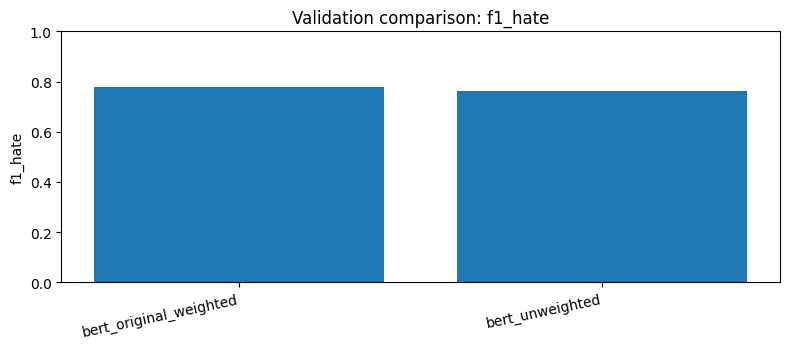

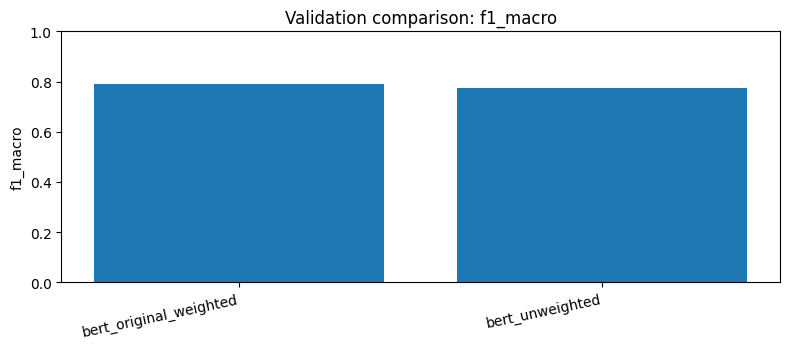

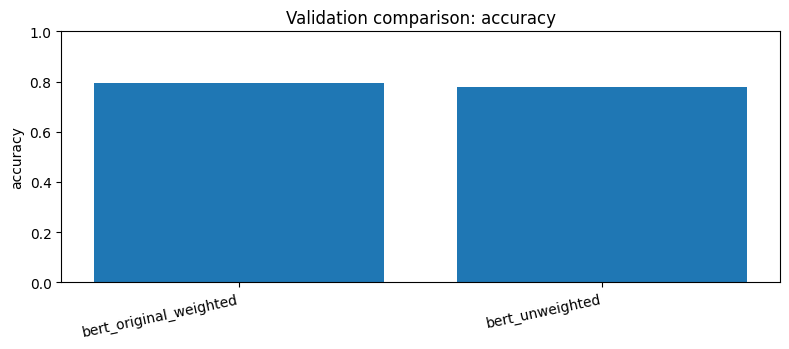

Download this file from Kaggle Output: /kaggle/working/ARTI502_Topic6_Section16_Weight_Ablation_Results.zip
Model checkpoint is saved separately in: /kaggle/working/ARTI502_Topic6_Outputs/section16_weight_ablation


In [ ]:
# Comparison on VALIDATION only. Do not rank by test scores.
original={'experiment':'bert_original_weighted','weights':'[0.8626, 1.1895]',
          'accuracy':0.793,'f1_hate':0.777180,'f1_macro':0.791951,'roc_auc':0.871869}
results=[original,unweighted_result]

# OPTIONAL second, explicitly exploratory cost-sensitive experiment.
# Unlike a pure false-positive penalty, these class weights increase loss for ALL errors on non-hate samples.
if RUN_FP_WEIGHTED_EXPERIMENT:
    penalty_result=train_trial('bert_nonhate_weight_1p5',weights=[1.5,1.0])
    results.append(penalty_result)

comparison=pd.DataFrame(results)
comparison.to_csv(ROOT/'validation_weight_ablation_comparison.csv',index=False)
print(comparison[['experiment','weights','accuracy','f1_hate','f1_macro','roc_auc']].to_string(index=False))

for metric in ['f1_hate','f1_macro','accuracy']:
    plt.figure(figsize=(8,3.6))
    plt.bar(comparison.experiment,comparison[metric]); plt.ylim(0,1)
    plt.ylabel(metric); plt.title(f'Validation comparison: {metric}')
    plt.xticks(rotation=12,ha='right');plt.tight_layout()
    plt.savefig(ROOT/f'validation_comparison_{metric}.png',dpi=160,bbox_inches='tight')
    plt.show()

summary={'description':'Exploratory class-weight ablation using official TweetEval hate training and validation only.',
         'warning':'Original model/test scores have already been observed; this is not a new independent test evaluation.',
         'config':{'seed':SEED,'model':BERT_NAME,'epochs':EPOCHS,'batch_size':BATCH_SIZE,'lr':LEARNING_RATE,'max_length':MAX_LEN},
         'comparison':comparison.fillna('').to_dict(orient='records')}
(ROOT/'experiment_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf8')
archive=Path('/kaggle/working/ARTI502_Topic6_Section16_Weight_Ablation_Results.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in ROOT.iterdir():
        if file.suffix in ('.csv','.png','.json'):
            z.write(file,arcname=file.name)
print('Download this file from Kaggle Output:',archive)
print('Model checkpoint is saved separately in:', ROOT)


### 17.5 Discussion of the Class-Weight Ablation Experiment

To investigate the effect of class weighting, an additional BERT model was fine-tuned using the same training and validation data and hyperparameter configuration, but without class weights in the cross-entropy loss.

The original weighted BERT achieved a validation accuracy of **79.3%**, Hate-class F1 of **77.72%**, and Macro F1 of **79.20%**. The unweighted BERT achieved **77.7% accuracy**, **76.35% Hate-class F1**, and **77.63% Macro F1**.

Removing class weights did not improve validation performance. Although the difference was relatively small, the weighted model performed better across the main evaluation metrics.

These findings suggest that class weighting was beneficial under the tested configuration. However, the experiment does not establish that class weighting caused the large difference between validation and test performance.

The original weighted BERT remains the preferred model based on validation performance. Further experiments could investigate alternative regularization settings, optimizer configurations, and model calibration.

**Limitation:** This additional experiment was conducted after inspecting the original test results and should therefore be interpreted as exploratory optimization rather than an independent test evaluation.